# Numerical Exercises 5
In quantum physics a **wave function**, $\Psi$, is a mathematical description of the state of a quantum system. The wave function is a complex-valued probability amplitude, and the probabilities for the possible results of measurements made on the system can be derived from it.

For now on, let's consider the simple case of a non-relativistic single particle, without spin, in three spatial dimensions. The state of such a particle is completely described by its wave function, $\Psi(\vec{r},t)$, where $\vec{r}$ is position and $t$ is time.

For one spinless particle, if the wave function is interpreted as a probability amplitude, the square modulus of the wave function, $|\Psi(\vec{r},t)|^2$, is interpreted as the probability density that the particle is at $\vec{r}$ at time $t$. Once we have a probability density, we can use Monte Carlo ...

#### Hydrogen atom
The wave functions of the eigenstates of an electron in a Hydrogen atom (this is the only atom for which the Schroedinger equation has been solved exactly) are expressed in terms of spherical harmonics and generalized Laguerre polynomials. It is convenient to use spherical coordinates, and the wave function can be separated into functions of each coordinate:

$$
\Psi_{n,l,m}(r,\theta,\phi)=
\sqrt{\left(\frac{2}{na_0}\right)^3 \frac{(n-l-1)!}{2n[(n+l)!]}}
e^{-r/na_0}\left(\frac{2r}{na_0}\right)^l L_{n-l-1}^{2l+1}\left(\frac{2r}{na_0}\right)
Y_l^m(\theta,\phi)
$$

where $a_0=4\pi\epsilon_0\hbar^2/m_e e^2=0.0529$ nm is the Bohr radius, $L_{n-l-1}^{2l+1}$ are the generalized Laguerre polynomials of degree $n-l-1$, $n=1,2,...$ is the principal quantum number, $l=0,1, ..., n-1$ the azimuthal quantum number, $m=-l, -l+1, ..., l-1, l$ the magnetic quantum number.

For example, the ground state wave function is:
$$
\Psi_{1,0,0}(r,\theta,\phi)=
\frac{a_0^{-3/2}}{\sqrt{\pi}} e^{-r/a_0} 
$$
whereas one of the three $2p$ excited state is:
$$
\Psi_{2,1,0}(r,\theta,\phi)=
\frac{a_0^{-5/2}}{8}\sqrt{\frac{2}{\pi}} r e^{-r/2a_0} \cos(\theta)
$$
<span style="color:blue">Expectation values for the radius turns out to be exactly:
$$
\left\langle r \right\rangle_{\Psi_{1,0,0}} = \frac{3}{2}a_0
\quad
\left\langle r \right\rangle_{\Psi_{2,1,0}} = 5 a_0
$$
</span>


## Exercise 05.1


Use the Metropolis algorithm to sample $|\Psi_{1,0,0}(x,y,z)|^2$ and $|\Psi_{2,1,0}(x,y,z)|^2$ **in Cartesian coordinates** using, initially, an uniform transition probability $T(\vec{x}|\vec{y})$. Use the sampled positions to estimate $\left\langle r \right\rangle_{\Psi_{1,0,0}}$ and $\left\langle r \right\rangle_{\Psi_{2,1,0}}$. As usual, use data blocking and give an estimate of the statistical uncertainties.
<span style="color:red">Show a picture of your estimations of $\left\langle r \right\rangle_{\Psi_{1,0,0}}$ and $\left\langle r \right\rangle_{\Psi_{2,1,0}}$</span> and their uncertainties with a large number of *throws* $M$ (e.g. $M\ge 10^6$) as a function of the number of blocks, $N$</font>.

- Use Bohr radius units, $a_0$ for distances
- Choose the step of the uniform transition probability $T(\vec{x}|\vec{y})$ in order to obtain 50% of acceptance in both cases
- Choose a reasonable starting point in the 3D space and equilibrate your sampling before to start measuring the radius. What do you observe when you start very far from the origin?
- How large should be the number of Monte Carlo Metropolis steps in each block?
- <span style="color:red">If you use a multivariate normal transition probability $T(\vec{x}|\vec{y})$, i.e. a Gaussian for each coordinate, your results for $\left\langle r \right\rangle_{\Psi_{1,0,0}}$ and $\left\langle r \right\rangle_{\Psi_{2,1,0}}$ are equivalent?</span>

### **Solution**
### Metropolis Algorithm

The **Metropolis algorithm** (or **$M(RT)^2$** algorithm) is a Markov Chain Monte Carlo (MCMC) method used to generate a sequence of random samples from a probability distribution $p(\vec{x})$ for which direct sampling is difficult. A key advantage of this method is that it only requires the analytical expression of the target probability density $p(\vec{x})$, since any unknown normalization constant cancels out in the acceptance ratio.

The algorithm proceeds through the following iterative steps:

1. **Initialization:** Choose an initial starting point $\vec{x}_0$ in configuration space.
2. **Step proposal:** From the current position $\vec{x}_i$, propose a candidate point $\vec{x}_{i+1}$ according to a trial transition probability $T(\vec{x}_{i+1} | \vec{x}_i)$.
3. **Acceptance criterion:** Compute the acceptance probability defined by:
   $$A(\vec{x}_{i+1} | \vec{x}_i) = \min\left[1, \; \frac{p(\vec{x}_{i+1}) \, T(\vec{x}_i | \vec{x}_{i+1})}{p(\vec{x}_i) \, T(\vec{x}_{i+1} | \vec{x}_i)}\right]$$
   In this problem, the target distribution is given by the quantum probability density $p(\vec{x}) = |\Psi(\vec{x}, t)|^2$. Whenever the trial transition probability $T$ is symmetric (i.e., $T(\vec{x}_{i+1} | \vec{x}_i) = T(\vec{x}_i | \vec{x}_{i+1})$), the acceptance probability simplifies to:
   $$A(\vec{x}_{i+1} | \vec{x}_i) = \min\left[1, \; \frac{p(\vec{x}_{i+1})}{p(\vec{x}_i)}\right] = \min\left[1, \; \frac{|\Psi(\vec{x}_{i+1})|^2}{|\Psi(\vec{x}_i)|^2}\right]$$
   Consequently, proposed steps that lead to regions of higher probability density are always accepted, whereas moves toward lower probability regions are accepted with probability $p(\vec{x}_{i+1}) / p(\vec{x}_i)$.
4. **State update:** Draw a random number $r$ in the interval $[0, 1)$. If $r < A(\vec{x}_{i+1} | \vec{x}_i)$, the move is accepted and the new state is set to $\vec{x}_{i+1}$; otherwise, the move is rejected and the system stays at the current position $\vec{x}_{i+1} = \vec{x}_i$.


### Step Selection and the 50% Rule

Two distinct symmetric transition probabilities are implemented:
* **Uniform transition probability:** displacements along each Cartesian coordinate are drawn uniformly from the interval $[-\Delta, \Delta]$.
* **Multivariate normal transition probability:** displacements along each coordinate are drawn from a Gaussian distribution $\mathcal{N}(0, \Delta)$.

Moreover, the choice of the step parameter $\Delta$ is crucial for the efficiency of $M(RT)^2$:
* If $\Delta$ is **too large**, trial steps frequently land in regions of low probability, leading to high rejection rates and an inefficient exploration of the configuration space.
* If $\Delta$ is **too small**, proposed moves are accepted almost every time, but exploration becomes excessively slow due to high auto-correlation between successive samples.

To avoid these two issues, the emprical rule is to choose a step that gives a an average acceptance rate of approximately **50%**.

### Code

To sample the quantum probability densities via the Metropolis algorithm, the `Metro` class was implemented, inheriting directly from the base class `DataBlocking`. This architecture integrates the data blocking statistical framework directly with the specific random walk dynamics required for the $1s$ and $2p$ hydrogenoid wave functions.

The class keeps track of the walker's coordinates and drives the Markov chain through several primary methods. The constructor initializes the parameters, handles the random number generator, configures whether the target state is $1s$ or $2p$ alongside the proposal distribution type (uniform or Gaussian), places the walker at an initial position, and prepares the 3D scatter file. The private method `acceptance` evaluates the transition probability ratio $p(\vec{x}_{\text{new}})/p(\vec{x}_{\text{old}})$ for either the ground state or the excited state, properly handling the nodal plane $z=0$ where the density drops to zero. Proposing and updating the walker's state is handled by `attempt_step`, which draws trial Cartesian displacements from the selected proposal distribution and executes the Metropolis accept-reject check. Finally, `simulate_block` overrides the base virtual method from `DataBlocking` to execute a full block of Metropolis updates, accumulating the radial distance $r$ at each step to compute the block average while periodically logging spatial coordinates to track the 3D cloud.

A critical component of the simulation is the dynamic tuning of the step size to fulfill the empirical 50% acceptance rule, which is carried out by the method `auto_set_delta()`, that automatically tunes the step size parameter delta by running batches of trial moves until the acceptance rate falls within 50%±2%, scaling $\Delta$ down if too many moves are rejected or up if too many are accepted:

```cpp
void auto_set_delta() {                               // Optional method to auto-tune the step size for ~50% acceptance
     double target_acc = 0.5;
     double tolerance = 0.02;
     double acc_rate = 0.0;
     int trial_steps = 1000;
     int attempt = 0;
     int max_attempts = 100;
     while (attempt < max_attempts) {
          int acc = 0;
          for (int j = 0; j < trial_steps; j++) {
               if (attempt_step()) acc++;
          }
          acc_rate = double(acc) / trial_steps;
          if (abs(acc_rate - target_acc) < tolerance) {
               cout << "Auto-tuning complete: delta = " << delta << ", acceptance rate = " << acc_rate * 100 << "%" << endl;
               return;                                // Desired acceptance rate achieved, exit the method
          }
          if (acc_rate < target_acc) delta *= 0.9;    // Decrease step size if acceptance is too low
          else delta *= 1.1;                          // Increase step size if acceptance is too high
          attempt++;
     }
          
     cout << "Max attempts reached without achieving target acceptance rate. Final delta = " << delta << ", acceptance rate = " << acc_rate * 100 << "%" << endl;
}
```

### Results


In [30]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

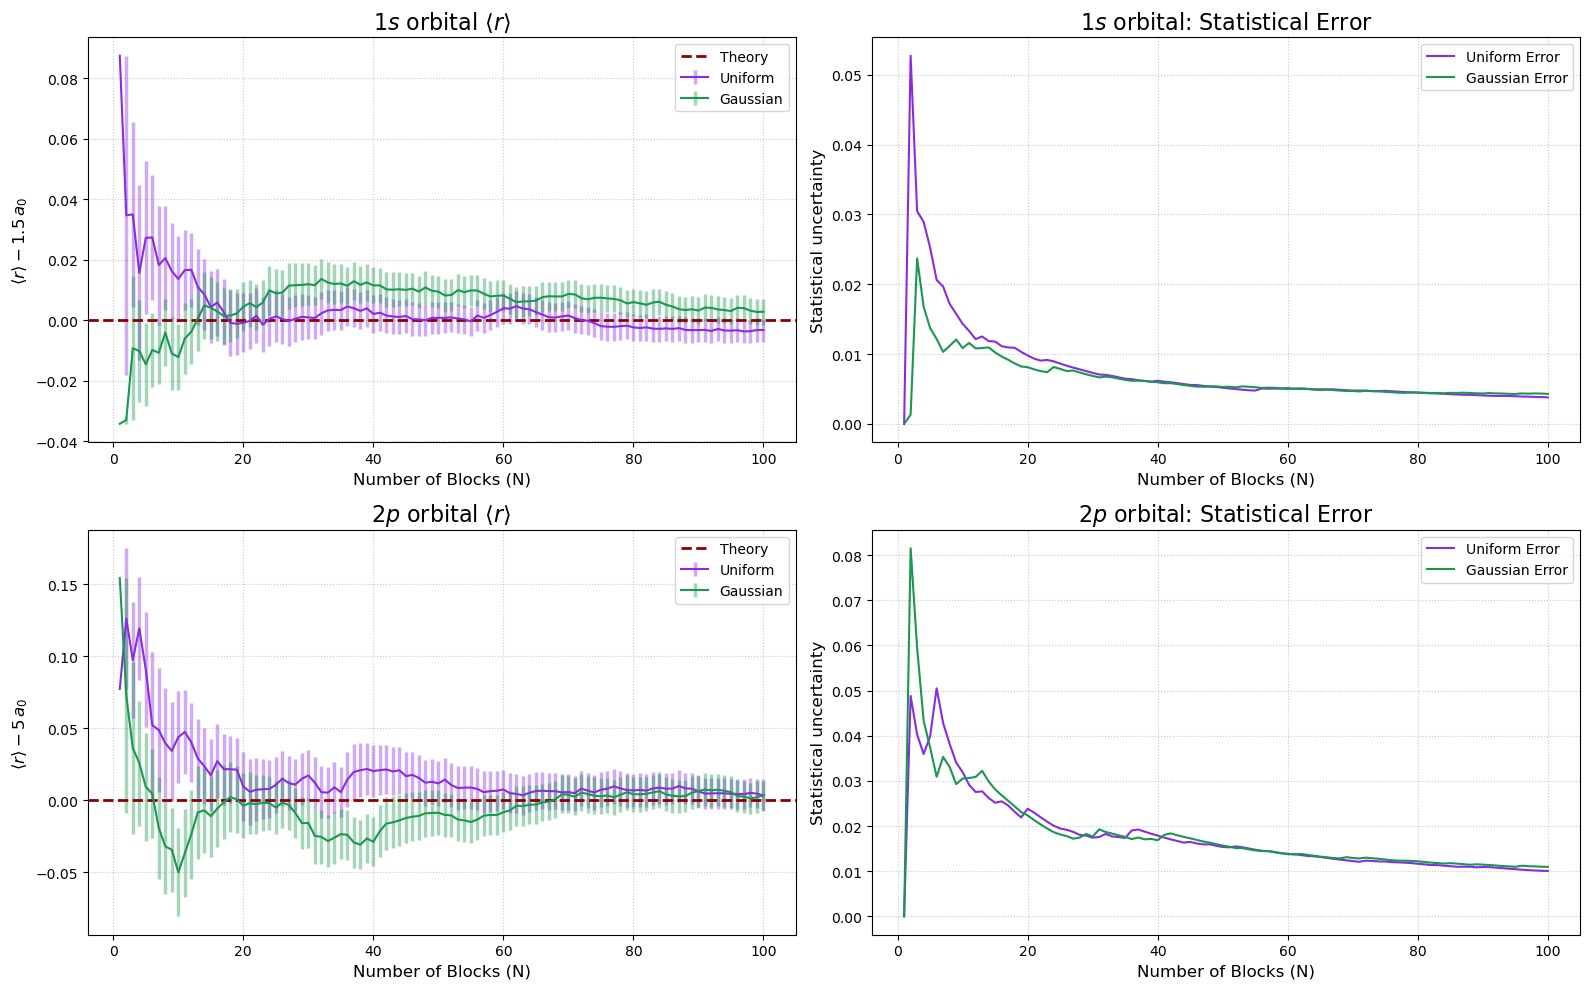

In [79]:
fig, axs = plt.subplots(2, 2, figsize=(16, 10))

b_1s_u, r_1s_u, err_1s_u = np.loadtxt("5.1/OUTPUT/metro_1s_unif.dat", usecols=(0, 2, 3), unpack=True)
b_1s_g, r_1s_g, err_1s_g = np.loadtxt("5.1/OUTPUT/metro_1s_gauss.dat", usecols=(0, 2, 3), unpack=True)

# 1s: Averages
axs[0, 0].errorbar(b_1s_u, r_1s_u, yerr=err_1s_u, label='Uniform', color='blueviolet', ecolor='#8A2BE266', elinewidth=2.5)
axs[0, 0].errorbar(b_1s_g, r_1s_g, yerr=err_1s_g, label='Gaussian', color="#199850", ecolor='#19985066', elinewidth=2.5)
axs[0, 0].axhline(0, color='darkred', linestyle='--', linewidth=2, label='Theory')
axs[0, 0].set_title(r"$1s$ orbital $\langle r \rangle$", fontsize=16)
axs[0, 0].set_xlabel("Number of Blocks (N)", fontsize=12)
axs[0, 0].set_ylabel(r"$\langle r \rangle - 1.5 \, a_0$", fontsize=12)
axs[0, 0].grid(True, linestyle=':', alpha=0.7)
axs[0, 0].legend()

# 1s: Errors
axs[0, 1].plot(b_1s_u, err_1s_u, label='Uniform Error', color='blueviolet')
axs[0, 1].plot(b_1s_g, err_1s_g, label='Gaussian Error', color='#199850')
axs[0, 1].set_title(r"$1s$ orbital: Statistical Error", fontsize=16)
axs[0, 1].set_xlabel("Number of Blocks (N)", fontsize=12)
axs[0, 1].set_ylabel("Statistical uncertainty", fontsize=12)
axs[0, 1].grid(True, linestyle=':', alpha=0.7)
axs[0, 1].legend()

b_2p_u, r_2p_u, err_2p_u = np.loadtxt("5.1/OUTPUT/metro_2p_unif.dat", usecols=(0, 2, 3), unpack=True)
b_2p_g, r_2p_g, err_2p_g = np.loadtxt("5.1/OUTPUT/metro_2p_gauss.dat", usecols=(0, 2, 3), unpack=True)

# 2p: Averages
axs[1, 0].errorbar(b_2p_u, r_2p_u, yerr=err_2p_u, label='Uniform', color='blueviolet', ecolor='#8A2BE266', elinewidth=2.5)
axs[1, 0].errorbar(b_2p_g, r_2p_g, yerr=err_2p_g, label='Gaussian', color="#199850", ecolor='#19985066', elinewidth=2.5)
axs[1, 0].axhline(0, color='darkred', linestyle='--', linewidth=2, label='Theory')
axs[1, 0].set_title(r"$2p$ orbital $\langle r \rangle$", fontsize=16)
axs[1, 0].set_xlabel("Number of Blocks (N)", fontsize=12)
axs[1, 0].set_ylabel(r"$\langle r \rangle - 5 \, a_0$", fontsize=12)
axs[1, 0].grid(True, linestyle=':', alpha=0.7)
axs[1, 0].legend()

# 2p: Errors
axs[1, 1].plot(b_2p_u, err_2p_u, label='Uniform Error', color='blueviolet')
axs[1, 1].plot(b_2p_g, err_2p_g, label='Gaussian Error', color='#199850')
axs[1, 1].set_title(r"$2p$ orbital: Statistical Error", fontsize=16)
axs[1, 1].set_xlabel("Number of Blocks (N)", fontsize=12)
axs[1, 1].set_ylabel("Statistical uncertainty", fontsize=12)
axs[1, 1].grid(True, linestyle=':', alpha=0.7)
axs[1, 1].legend()

plt.tight_layout()
plt.show()

**Plot parameters**
- $M=10^6$
- $N=10^2$
- $L=10^4$

The graphs illustrate the expectation values of the radial distance $\langle r \rangle$ and their corresponding statistical uncertainties as a function of the number of blocks $N$ for both the $1s$ and $2p$ orbitals. <br>
Both the Uniform and Gaussian transition probability distributions successfully converge to the exact quantum mechanical theoretical predictions.
Furthermore, there is **no significant difference** in the asymptotic behavior of the two sampling methods. As $N$ increases, the statistical errors for both the Uniform and Gaussian proposals decay and overlap almost perfectly. 

This behavior confirms a fundamental property of the Metropolis algorithm: as long as the transition probability $T(\mathbf{x}|\mathbf{y})$ is symmetric and the step size $\delta$ is properly tuned to ensure a reasonable acceptance rate, the specific shape of the proposal distribution (Uniform or Gaussian) does not affect the final expectation values nor the statistical precision of the Monte Carlo integration.
### 3D Orbital Visualization: Uniform vs. Gaussian Transition

The 3D scatter plots illustrate the spatial distribution of the sampled configurations for the Hydrogen orbitals. The visualizations display the spherically symmetric $1s$ orbital in the top row, and the characteristic dumbbell shape of the $2p$ orbital in the bottom row. 
This spatial equivalence provides a visual confirmation that the choice of the proposal distribution is indifferent to the final outcome: both methods correctly and equivalently sample the target probability density function $|\Psi(\vec{r})|^2$.

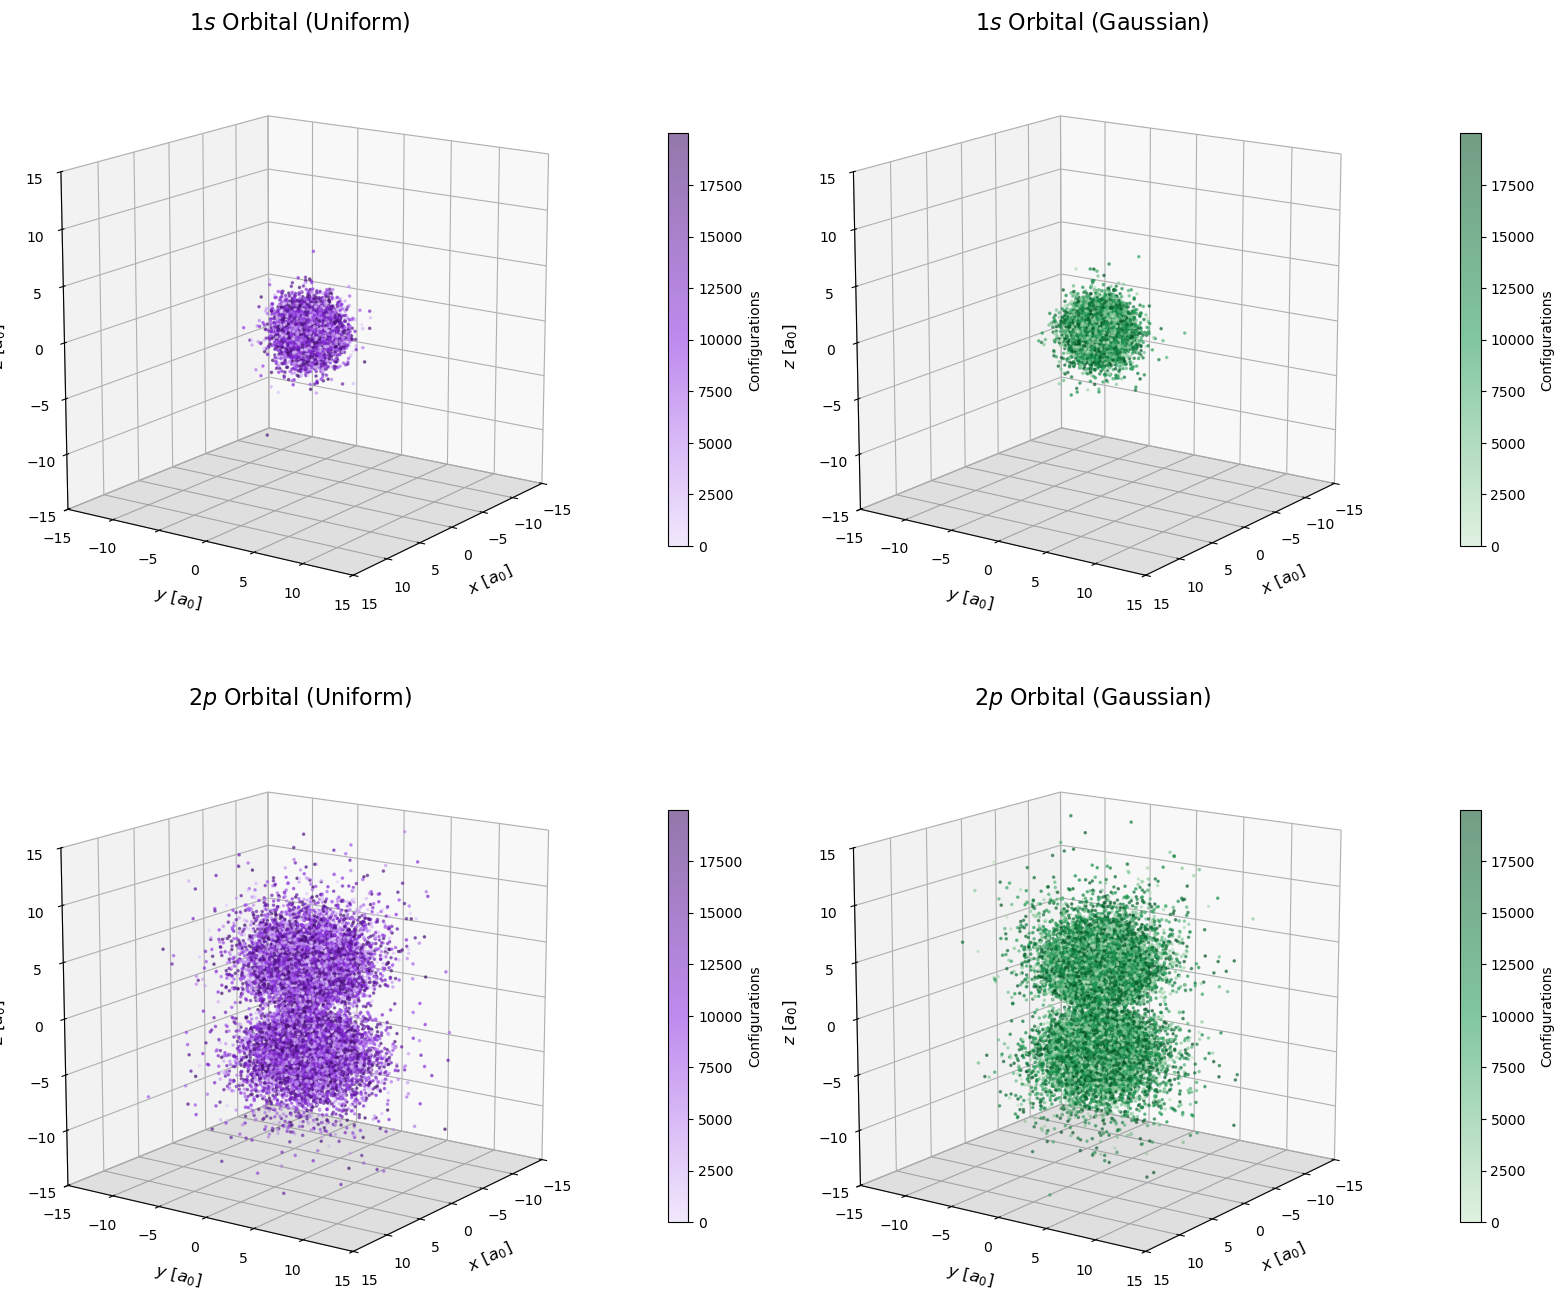

In [82]:
cmap_unif = LinearSegmentedColormap.from_list(
    "CustomPurple", ["#E6D6FA", "blueviolet", "#3B0A64"]
)
cmap_gauss = LinearSegmentedColormap.from_list(
    "CustomGreen", ["#C8E6C9", "#199850", "#004D20"]
)

lim = 15
view_elev = 15
view_azim = 35
plane_x, plane_y = np.meshgrid(np.linspace(-lim, lim, 10), np.linspace(-lim, lim, 10))
plane_z = np.full_like(plane_x, -lim)

def configure_axis(ax, title):
    ax.set_title(title, fontsize=16, pad=15)
    ax.set_xlabel(r"$x$ [$a_0$]", fontsize=12, labelpad=8)
    ax.set_ylabel(r"$y$ [$a_0$]", fontsize=12, labelpad=8)
    
    # Scritta dell'asse z in verticale
    ax.zaxis.set_rotate_label(False)
    ax.set_zlabel(r"$z$ [$a_0$]", fontsize=12, rotation=90, labelpad=8)

    ax.set_xlim([-lim, lim])
    ax.set_ylim([-lim, lim])
    ax.set_zlim([-lim, lim])

    ax.set_box_aspect([1, 1, 1])
    ax.view_init(elev=view_elev, azim=view_azim)
    ax.plot_surface(plane_x, plane_y, plane_z, color='gray', alpha=0.15, edgecolor='none')

fig = plt.figure(figsize=(16, 14))

# =========================================================
# 1. Row 1, Col 1: 1s Orbital - Uniform Transition
# =========================================================
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
x_1s_u, y_1s_u, z_1s_u = np.loadtxt("5.1/OUTPUT/scatter_1s_unif.dat", unpack=True)
steps_1s_u = np.arange(len(x_1s_u))

sc1 = ax1.scatter(x_1s_u, y_1s_u, z_1s_u, c=steps_1s_u, cmap=cmap_unif, marker='.', s=10, alpha=0.55)
configure_axis(ax1, r"$1s$ Orbital (Uniform)")
fig.colorbar(sc1, ax=ax1, shrink=0.6, pad=0.1, label="Configurations")

# =========================================================
# 2. Row 1, Col 2: 1s Orbital - Gaussian Transition
# =========================================================
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
x_1s_g, y_1s_g, z_1s_g = np.loadtxt("5.1/OUTPUT/scatter_1s_gauss.dat", unpack=True)
steps_1s_g = np.arange(len(x_1s_g))

sc2 = ax2.scatter(x_1s_g, y_1s_g, z_1s_g, c=steps_1s_g, cmap=cmap_gauss, marker='.', s=10, alpha=0.55)
configure_axis(ax2, r"$1s$ Orbital (Gaussian)")
fig.colorbar(sc2, ax=ax2, shrink=0.6, pad=0.1, label="Configurations")

# =========================================================
# 3. Row 2, Col 1: 2p Orbital - Uniform Transition
# =========================================================
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
x_2p_u, y_2p_u, z_2p_u = np.loadtxt("5.1/OUTPUT/scatter_2p_unif.dat", unpack=True)
steps_2p_u = np.arange(len(x_2p_u))

sc3 = ax3.scatter(x_2p_u, y_2p_u, z_2p_u, c=steps_2p_u, cmap=cmap_unif, marker='.', s=10, alpha=0.55)
configure_axis(ax3, r"$2p$ Orbital (Uniform)")
fig.colorbar(sc3, ax=ax3, shrink=0.6, pad=0.1, label="Configurations")

# =========================================================
# 4. Row 2, Col 2: 2p Orbital - Gaussian Transition
# =========================================================
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
x_2p_g, y_2p_g, z_2p_g = np.loadtxt("5.1/OUTPUT/scatter_2p_gauss.dat", unpack=True)
steps_2p_g = np.arange(len(x_2p_g))

sc4 = ax4.scatter(x_2p_g, y_2p_g, z_2p_g, c=steps_2p_g, cmap=cmap_gauss, marker='.', s=10, alpha=0.55)
configure_axis(ax4, r"$2p$ Orbital (Gaussian)")
fig.colorbar(sc4, ax=ax4, shrink=0.6, pad=0.1, label="Configurations")

plt.tight_layout()
plt.show()

### Equilibration from a Distant Configuration

To study the thermalization phase of the Metropolis algorithm, the simulation was intentionally initialized at a position far from the origin ($x=100, y=100, z=100$). 

Instead of computing block averages, the instantaneous spatial coordinates and the radial distance $r$ were recorded for each individual, consecutive Monte Carlo step. This step-by-step sampling method allows us to explicitly track the trajectory of the particle as it "falls" toward the highest probability density region (the nucleus) and eventually reaches a stationary state, properly fluctuating around the theoretical expectation value.

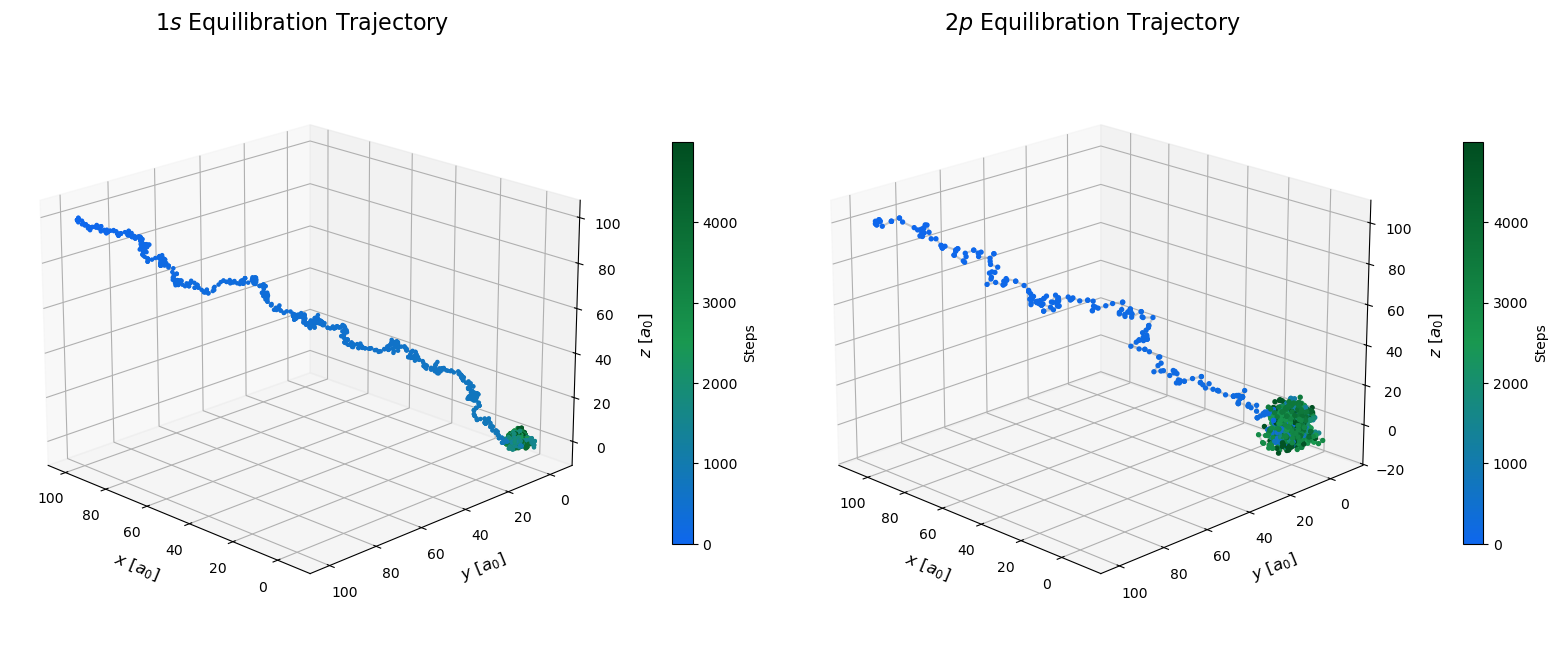

In [83]:
# Colormap
cmap_unif = LinearSegmentedColormap.from_list(
    "CustomGreen", ["#0E67ED", "#199850", "#004D20"]
)

view_elev = 20
view_azim = 135

def configure_3d_axis(ax, title):
    ax.set_title(title, fontsize=16, pad=15)
    ax.set_xlabel(r"$x$ [$a_0$]", fontsize=12, labelpad=8)
    ax.set_ylabel(r"$y$ [$a_0$]", fontsize=12, labelpad=8)

    ax.zaxis.set_rotate_label(False)
    ax.set_zlabel(r"$z$ [$a_0$]", fontsize=12, rotation=90, labelpad=8)
 
    ax.view_init(elev=view_elev, azim=view_azim)

fig = plt.figure(figsize=(16, 7))

# =========================================================
# 1. Col 1: 1s Orbital Equilibration (Far Uniform)
# =========================================================
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
x_1s, y_1s, z_1s = np.loadtxt("5.1/OUTPUT/scatter_1s_far_unif.dat", usecols=(1, 2, 3), unpack=True)
steps_1s = np.arange(len(x_1s))

ax1.plot(x_1s, y_1s, z_1s, color='darkgray', linewidth=1.5, alpha=0.6)
sc1 = ax1.scatter(x_1s, y_1s, z_1s, c=steps_1s, cmap=cmap_unif, marker='o', s=5, alpha=1.0)

configure_3d_axis(ax1, r"$1s$ Equilibration Trajectory")
fig.colorbar(sc1, ax=ax1, shrink=0.6, pad=0.1, label="Steps")

# =========================================================
# 2. Col 2: 2p Orbital Equilibration (Far Uniform)
# =========================================================
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
x_2p, y_2p, z_2p = np.loadtxt("5.1/OUTPUT/scatter_2p_far_unif.dat", usecols=(1, 2, 3), unpack=True)
steps_2p = np.arange(len(x_2p))

ax2.plot(x_2p, y_2p, z_2p, color='darkgray', linewidth=1.5, alpha=0.6)
sc2 = ax2.scatter(x_2p, y_2p, z_2p, c=steps_2p, cmap=cmap_unif, marker='o', s=8, alpha=1.0)

configure_3d_axis(ax2, r"$2p$ Equilibration Trajectory")
fig.colorbar(sc2, ax=ax2, shrink=0.6, pad=0.1, label="Steps")

plt.tight_layout()
plt.show()

### Optimization of the Block Size ($L$)

To determine the appropriate block size $L$ for the Data Blocking method, it is essential to study the behavior of the statistical error as a function of $L$, looking for saturation that indicates the fact that the system's correlation time has been overcome. The following graph shows the error trend for a simulation of $M = 10^6$ steps. 



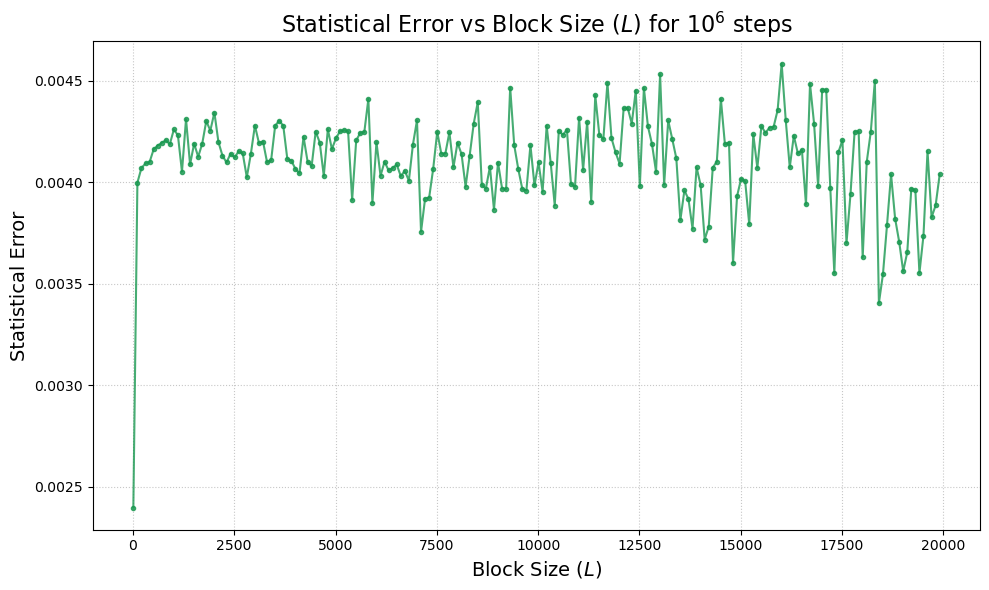

In [84]:
r_istantaneo = np.loadtxt("5.1/OUTPUT/1s_correl.dat", usecols=(4))

def calculate_block_error(data, L):
    N = len(data) // L
    if N < 2: return 0 
    
    truncated_data = data[:N*L]
    blocks = truncated_data.reshape(N, L).mean(axis=1)
    error = np.std(blocks, ddof=1) / np.sqrt(N)
    return error
L_values = np.arange(10, 20001, 100) 
errors = []

for L in L_values:
    errors.append(calculate_block_error(r_istantaneo, L))

plt.figure(figsize=(10, 6))
plt.plot(L_values, errors, marker='o', markersize=3, linestyle='-', color='#199850', alpha=0.8)
plt.title(r"Statistical Error vs Block Size ($L$) for $10^6$ steps", fontsize=16)
plt.xlabel("Block Size ($L$)", fontsize=14)
plt.ylabel("Statistical Error", fontsize=14)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

As can be observed, for very small block sizes, the calculated statistical error is artificially low (around 0.0025). This phenomenon is a direct consequence of the intrinsic autocorrelation of the Markov chain generated by the Metropolis algorithm, which leads to a severe underestimation of the uncertainty if the data are naively treated as independent. 

As the block size $L$ increases, the error grows rapidly until it stabilizes within a plateau region. For values of $L$ located on this plateau (such as our choice of $L = 10000$), the blocks lose their statistical "memory" of one another and can be treated as fully independent random variables.